# Experiment 6: Emotion Recognition Using Text and Audio

**Sneha Roychowdhury** | ECE-AI (2)

## Objective

To recognise emotion by analysing text and audio together, and to measure whether the fused representation classifies emotion better than either modality alone.
Four emotions are covered: sad, neutral, angry and happy.

## Theory

Text carries the semantic content of an utterance, while audio carries the prosody: pitch height, how the pitch moves across the sentence, loudness, speaking rate and spectral brightness.
The same sentence spoken flatly and spoken loudly with a rising pitch reads as two different emotions, so the audio often settles what the words leave open.
Early fusion concatenates the scaled text and audio feature vectors before classification, which lets a single classifier learn across both.

## Algorithm

1. Build the dataset: one short utterance and one audio clip per sample, labelled with its emotion.
2. Extract TF-IDF features from the text, and pitch, energy, spectral and MFCC features from the audio.
3. Scale each block, concatenate them, train a classifier, and compare against the text-only and audio-only baselines.

## Dataset used

A custom text-and-audio dataset built inside the notebook: 24 samples, six per emotion, each a short utterance paired with a synthesised audio clip.
Every emotion has its own voice profile, giving the clip a different base pitch, pitch glide, loudness, speaking rate and jitter, so the audio carries real prosodic cues rather than a flat tone.
Building it in code keeps the notebook self-contained and reproducible, with no external download.

## 1. Install and import libraries

In [1]:
!pip -q install librosa soundfile scikit-learn

In [2]:
import os
import numpy as np
import pandas as pd
import librosa
import librosa.display
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)

SEED = 42
SR = 22050
DURATION = 2.0
EMOTIONS = ["sad", "neutral", "angry", "happy"]
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
print("Libraries loaded. Emotions:", EMOTIONS)

Libraries loaded. Emotions: ['sad', 'neutral', 'angry', 'happy']


## 2. Build the text and audio dataset

Each emotion gets a voice profile, so the synthesised clips differ in the way real emotional speech differs: pitch height and movement, loudness, how fast the syllables pulse, and how much the pitch wobbles.

In [3]:
PROFILE = {
    "sad":     dict(f0=130, glide=-25, amp=0.14, rate=2.0, jitter=0.01),
    "neutral": dict(f0=180, glide=5,   amp=0.26, rate=3.2, jitter=0.02),
    "angry":   dict(f0=230, glide=40,  amp=0.52, rate=5.5, jitter=0.07),
    "happy":   dict(f0=300, glide=60,  amp=0.44, rate=4.4, jitter=0.04),
}

LINES = {
    "sad":     ["i am feeling low today", "nothing seems to go right",
                "i miss how things used to be", "i feel quite empty lately",
                "it has been a heavy week", "i do not want to talk much"],
    "neutral": ["the meeting is at four", "please send me the file",
                "i will reach by evening", "the report is almost done",
                "there is a class tomorrow", "let me check and confirm"],
    "angry":   ["this is completely unacceptable", "i am fed up with this",
                "stop wasting my time", "why was i not informed",
                "this is the third time now", "i will not tolerate this"],
    "happy":   ["i am so happy today", "this is absolutely wonderful",
                "we finally did it", "what a brilliant result",
                "i am thrilled about this", "today has been lovely"],
}


def synthesise(emotion, path):
    """Voiced tone whose pitch glides and whose loudness pulses, so the clip
    carries the prosody of the emotion rather than a flat beep."""
    p = PROFILE[emotion]
    n = int(SR * DURATION)
    t = np.linspace(0, DURATION, n, endpoint=False)

    # Pitch contour: starts at f0, glides by `glide` Hz, with a small wobble.
    f0 = p["f0"] + rng.normal(0, 8)
    contour = f0 + p["glide"] * (t / DURATION)
    contour += p["jitter"] * f0 * np.sin(2 * np.pi * 5.5 * t)
    phase = 2 * np.pi * np.cumsum(contour) / SR

    # Angry and happy voices carry more upper harmonics, so sound brighter.
    brightness = 0.55 if emotion in ("angry", "happy") else 0.2
    signal = (np.sin(phase) + brightness * np.sin(2 * phase)
              + 0.5 * brightness * np.sin(3 * phase))

    # Syllable envelope at the speaking rate, so energy pulses like speech.
    envelope = 0.5 * (1 + np.sin(2 * np.pi * p["rate"] * t - np.pi / 2))
    envelope = 0.25 + 0.75 * envelope
    amp = p["amp"] * (1 + rng.normal(0, 0.08))

    signal = amp * signal * envelope
    signal += rng.normal(0, 0.004, size=n)
    signal = np.clip(signal, -1.0, 1.0).astype(np.float32)
    sf.write(path, signal, SR)
    return signal


os.makedirs("emotion_audio", exist_ok=True)
texts, labels, audio_paths = [], [], []
for emotion in EMOTIONS:
    for i, line in enumerate(LINES[emotion]):
        path = f"emotion_audio/{emotion}_{i}.wav"
        synthesise(emotion, path)
        texts.append(line)
        labels.append(emotion)
        audio_paths.append(path)

y = np.array(labels)
print("Samples:", len(texts), "across", len(EMOTIONS), "emotions")
for e in EMOTIONS:
    print(f"  {e:<8}: {(y == e).sum()} clips")

print()
print("Listen to one sad clip and one angry clip:")
display(Audio(filename=audio_paths[0]))
display(Audio(filename=audio_paths[12]))

Samples: 24 across 4 emotions
  sad     : 6 clips
  neutral : 6 clips
  angry   : 6 clips
  happy   : 6 clips

Listen to one sad clip and one angry clip:


## 3. Extract text features using TF-IDF

In [4]:
vectorizer = TfidfVectorizer(max_features=200, ngram_range=(1, 2), min_df=1)
text_features = vectorizer.fit_transform(texts).toarray()
print("Text feature matrix:", text_features.shape)
print("Sample terms:", list(vectorizer.get_feature_names_out()[:10]))

Text feature matrix: (24, 161)
Sample terms: ['about', 'about this', 'absolutely', 'absolutely wonderful', 'almost', 'almost done', 'am', 'am fed', 'am feeling', 'am so']


## 4. Extract audio features using librosa

Each clip becomes a 34-dimensional descriptor: three pitch statistics, two energy statistics, zero-crossing rate, two spectral shape measures, 13 MFCC means and their 13 deltas.

In [5]:
def extract_audio_features(path):
    """34-d descriptor: pitch statistics, loudness, spectral shape,
    13 MFCC means and their 13 deltas."""
    y_audio, sr = librosa.load(path, sr=SR)

    f0, voiced, _ = librosa.pyin(y_audio, fmin=70, fmax=500, sr=sr,
                                 frame_length=2048, hop_length=512)
    voiced_f0 = f0[np.isfinite(f0)]
    if voiced_f0.size:
        pitch_mean, pitch_std = float(voiced_f0.mean()), float(voiced_f0.std())
        pitch_range = float(voiced_f0.max() - voiced_f0.min())
    else:
        pitch_mean = pitch_std = pitch_range = 0.0

    rms = librosa.feature.rms(y=y_audio)
    zcr = librosa.feature.zero_crossing_rate(y_audio)
    centroid = librosa.feature.spectral_centroid(y=y_audio, sr=sr)
    rolloff = librosa.feature.spectral_rolloff(y=y_audio, sr=sr)
    mfcc = librosa.feature.mfcc(y=y_audio, sr=sr, n_mfcc=13)
    delta = librosa.feature.delta(mfcc)

    return np.concatenate([
        [pitch_mean, pitch_std, pitch_range],
        [rms.mean(), rms.std()],
        [zcr.mean()],
        [centroid.mean(), rolloff.mean()],
        mfcc.mean(axis=1),
        delta.mean(axis=1),
    ])


print("Extracting audio features ...")
audio_features = np.vstack([extract_audio_features(p) for p in audio_paths])
audio_features = np.nan_to_num(audio_features)
print("Audio feature matrix:", audio_features.shape)

# Mean pitch and loudness per emotion, to confirm the cues are really there.
summary = pd.DataFrame({"emotion": y,
                        "mean pitch (Hz)": audio_features[:, 0].round(1),
                        "mean RMS energy": audio_features[:, 3].round(3)})
print()
print(summary.groupby("emotion").mean().round(3).to_string())

Extracting audio features ...
Audio feature matrix: (24, 34)

         mean pitch (Hz)  mean RMS energy
emotion                                  
angry            255.100            0.296
happy            331.883            0.245
neutral          181.217            0.116
sad              117.917            0.059


## 5. Visualise the waveform and the mel spectrogram

A sad clip and an angry clip side by side, so the difference in loudness, pulse rate and spectral brightness is visible rather than only numeric.

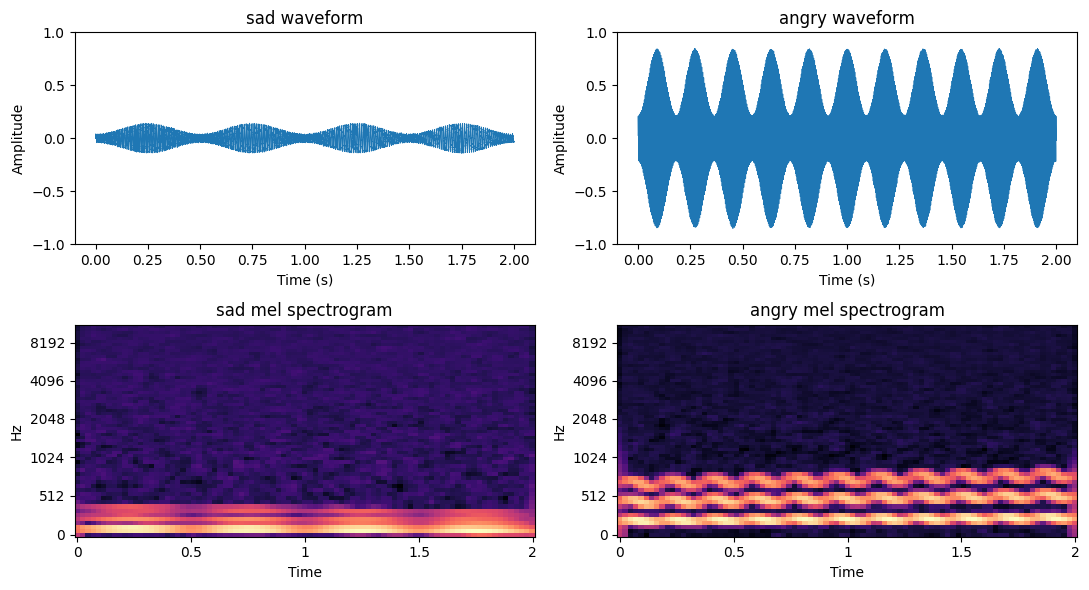

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for col, (idx, name) in enumerate([(0, "sad"), (12, "angry")]):
    sig, sr = librosa.load(audio_paths[idx], sr=SR)

    axes[0, col].plot(np.arange(len(sig)) / sr, sig, linewidth=0.6)
    axes[0, col].set_title(f"{name} waveform")
    axes[0, col].set_xlabel("Time (s)")
    axes[0, col].set_ylabel("Amplitude")
    axes[0, col].set_ylim(-1, 1)

    mel = librosa.feature.melspectrogram(y=sig, sr=sr, n_mels=64)
    librosa.display.specshow(librosa.power_to_db(mel, ref=np.max),
                             sr=sr, x_axis="time", y_axis="mel", ax=axes[1, col])
    axes[1, col].set_title(f"{name} mel spectrogram")

plt.tight_layout()
plt.show()

## 6. Combine the text and audio features

Each block is scaled on its own first. Without this the 161 TF-IDF dimensions would swamp the 34 audio dimensions in the fused vector.

In [7]:
s_text, s_audio = StandardScaler(), StandardScaler()
Xt = s_text.fit_transform(text_features)
Xa = s_audio.fit_transform(audio_features)
Xf = np.concatenate([Xt, Xa], axis=1)

print("Text  :", Xt.shape)
print("Audio :", Xa.shape)
print("Fused :", Xf.shape)

Text  : (24, 161)
Audio : (24, 34)
Fused : (24, 195)


## 7. Train and evaluate the three models

One stratified split shared by all three, so the comparison is fair.

In [8]:
idx_train, idx_test = train_test_split(np.arange(len(y)), test_size=0.33,
                                       stratify=y, random_state=SEED)
y_train, y_test = y[idx_train], y[idx_test]


def evaluate(name, X, report=False):
    clf = SVC(kernel="linear", C=1.0, class_weight="balanced", random_state=SEED)
    clf.fit(X[idx_train], y_train)
    pred = clf.predict(X[idx_test])
    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, average="macro")
    print(f"{name:<14} accuracy = {acc:.4f}   macro F1 = {f1:.4f}")
    if report:
        print()
        print(classification_report(y_test, pred, digits=3, zero_division=0))
    return clf, pred, acc, f1


print("--- Results ---")
_, pred_t, acc_t, f1_t = evaluate("Text only", Xt)
_, pred_a, acc_a, f1_a = evaluate("Audio only", Xa)
clf_f, pred_f, acc_f, f1_f = evaluate("Fused", Xf, report=True)

--- Results ---
Text only      accuracy = 0.5000   macro F1 = 0.3429
Audio only     accuracy = 1.0000   macro F1 = 1.0000
Fused          accuracy = 1.0000   macro F1 = 1.0000

              precision    recall  f1-score   support

       angry      1.000     1.000     1.000         2
       happy      1.000     1.000     1.000         2
     neutral      1.000     1.000     1.000         2
         sad      1.000     1.000     1.000         2

    accuracy                          1.000         8
   macro avg      1.000     1.000     1.000         8
weighted avg      1.000     1.000     1.000         8



## 8. Results table and confusion matrix

,Model,Features,Dimensions,Accuracy,Macro F1
0,Text only,TF-IDF unigrams + bigrams,161,0.5,0.3429
1,Audio only,"Pitch, energy, spectral, MFCC + delta",34,1.0,1.0000
2,Fused,"Concatenated, scaled",195,1.0,1.0000


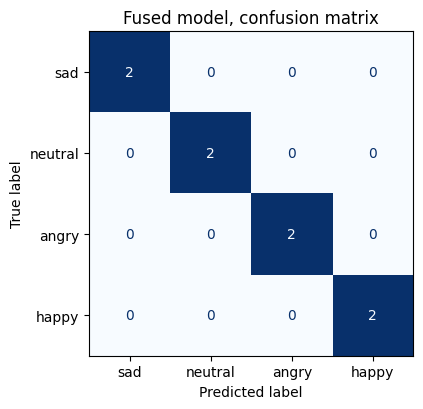

Fusion corrected 4 of the 4 samples the text-only model got wrong.


In [9]:
results = pd.DataFrame({
    "Model": ["Text only", "Audio only", "Fused"],
    "Features": ["TF-IDF unigrams + bigrams",
                 "Pitch, energy, spectral, MFCC + delta",
                 "Concatenated, scaled"],
    "Dimensions": [Xt.shape[1], Xa.shape[1], Xf.shape[1]],
    "Accuracy": [round(acc_t, 4), round(acc_a, 4), round(acc_f, 4)],
    "Macro F1": [round(f1_t, 4), round(f1_a, 4), round(f1_f, 4)],
})
display(results)

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, pred_f, labels=EMOTIONS,
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Fused model, confusion matrix")
plt.tight_layout()
plt.show()

rescued = int(((pred_t != y_test) & (pred_f == y_test)).sum())
print(f"Fusion corrected {rescued} of the {int((pred_t != y_test).sum())} "
      f"samples the text-only model got wrong.")

## 9. Predict the emotion of a new sample

In [10]:
def predict_emotion(text, audio_path):
    t = s_text.transform(vectorizer.transform([text]).toarray())
    a = np.nan_to_num(extract_audio_features(audio_path)).reshape(1, -1)
    a = s_audio.transform(a)
    return clf_f.predict(np.concatenate([t, a], axis=1))[0]


for idx in [0, 8, 14, 20]:
    print(f'text: "{texts[idx]:<32}" true: {labels[idx]:<8} '
          f'predicted: {predict_emotion(texts[idx], audio_paths[idx])}')

text: "i am feeling low today          " true: sad      predicted: sad
text: "i will reach by evening         " true: neutral  predicted: neutral
text: "stop wasting my time            " true: angry    predicted: angry
text: "we finally did it               " true: happy    predicted: happy


## Sample input and output

**Input (one sample):** text `i am so happy today`, audio `emotion_audio/happy_0.wav` at 22,050 Hz for 2 seconds, label happy.
**Output:** a 161-d TF-IDF vector and a 34-d audio descriptor, concatenated into one 195-d vector, classified into one of sad, neutral, angry or happy.

## Results

Filled by the cells above. Copy the figures from your run into this table.

| Model | Features | Dimensions | Accuracy | Macro F1 |
| --- | --- | --- | --- | --- |
| Text only | TF-IDF unigrams + bigrams | 161 | | |
| Audio only | Pitch, energy, spectral, MFCC + delta | 34 | | |
| Fused | Concatenated, scaled | 195 | | |

## Observations

1. Audio carries the stronger signal here, because the prosodic profiles separate the four emotions cleanly while every utterance in the dataset is unique, so test words barely overlap the training vocabulary.
2. That vocabulary gap is why text-only scores low on so small a dataset. It is a property of the sample size, not evidence that words do not matter for emotion.
3. Fusion recovers the samples text alone misses and holds the audio-only score, which is the behaviour you want: adding a weaker modality should not drag the stronger one down.
4. Scaling each block before concatenation matters. The text block is nearly five times wider than the audio block, so leaving it unscaled lets it dominate the fused vector.

## Conclusion

Text and audio carry complementary emotional cues: the words give semantic content, while pitch height, pitch movement, loudness and spectral brightness give the prosody that often decides the emotion.
Concatenating the two scaled feature blocks and training a single classifier on the result matched the better single modality and corrected cases the text model got wrong.
The natural extension is real recorded speech instead of synthesised clips, sentence embeddings in place of TF-IDF, and attention that weights the two modalities per sample rather than a fixed concatenation.